# Reconstruire un document assemblé — l'élimination des redondances vectorielles

**Série Compression — carnet 08 — second cas du [Concern du 16/11](https://github.com/jsboige/CoursIA/issues/26917)**

**Navigation** : [Index de la série](README.md) | [Compression-07b — Triage par LLM sous Semantic Kernel](Compression-07b-Triage-LLM-Semantic-Kernel-Python.ipynb) | [jumeau Python](Compression-08-Assemblage-Vectoriel-Python.ipynb)

Le premier cas du même programme — la **provenance d'un média bitmap**, mesurée dans le [volet provenance](https://github.com/jsboige/CoursIA/pull/26920) qui étend le carnet 07b — traitait des formes pleines dont la géométrie détermine les pixels : l'identité au pixel y prouve que le générateur proposé est le bon. Ce volet écrivait noir sur blanc ce qu'il ne prétendait pas faire : un document avec du texte, une courbe lissée ou un dégradé sortait de sa famille.

Ce carnet prend ce cas laissé de côté, tel que le Concern le formule : *« identifier la logique d'assemblage vectoriel des parties d'un document mis en forme, et scripter sa reconstruction en éliminant les redondances »*. Deux idées distinctes, traitées comme telles :

| Point | Cas 1 — bitmap ([#26920](https://github.com/jsboige/CoursIA/pull/26920)) | Ce carnet (cas 2) |
|---|---|---|
| Artefact | image de formes pleines (PNG) | structure de forme **SVG** : blocs stylés, grille, marges |
| Redondance | aucune — chaque forme est unique | **structurelle** — les mêmes styles, marges et placements reviennent |
| Preuve d'identité | pixel à pixel sur le raster | **reconstruction dépendante** : octets du document rejoué + modèle |
| Où est le gain | rapport artefact/script qui ne devient gagnant qu'en haute résolution | la redondance éliminée grossit **avec la répétition**, à toute échelle |

La thèse à réfuter est la même que celle de 07b, déplacée : ce n'est pas « le triage bat-il le traitement indifférencié » mais **« la reconstruction par assemblage est-elle plus petite que le document qu'elle reproduit, et le rapport s'améliore-t-il quand le document grossit ? »** La réponse est mesurée, pas supposée — et le garde d'identité doit **refuser** un reconstructeur qui triche.

## Prérequis et matériel

Ce carnet s'exécute **de bout en bout ou pas du tout**. Il a besoin de :

- `System.Xml.Linq` (la construction et la re-sérialisation XML du document) — présent dans l'environnement de la série ;
- la bibliothèque standard uniquement pour le reste : un générateur **MT19937** faithful à la graine fixée, `System.Security.Cryptography` (SHA-256), `System.IO.Compression` (Deflate) .

**Aucun appel de modèle dans ce carnet.** La partie « le LLM isole les segments et propose la recette » du Concern est délibérément hors périmètre : la section Limites dit ce que ce choix coûte et ce qu'il faudrait pour le lever. Ici, l'isolation des segments est **déterministe** — c'est la condition pour que la mesure de la redondance éliminée et le garde d'identité disent quelque chose : un candidat proposé par un modèle ne prouve rien tant qu'il n'a pas été rejoué et comparé octet à octet, et le mécanisme de cette comparaison est ce que ce carnet construit.

La graine est fixée une fois pour toutes : deux exécutions produisent le même document, la même recette et les mêmes mesures.

In [1]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.IO;
using System.Linq;
using System.Numerics;
using System.Security.Cryptography;
using System.Text;
using System.Xml;
using System.Xml.Linq;

public sealed record StyleDef(string Font, int Taille, bool Gras);
public sealed record Bloc(string Style, string Texte, int Col, int Ligne);

public sealed class Document
{
    public int MargeG { get; }
    public int MargeH { get; }
    public int PasCol { get; }
    public int PasLigne { get; }
    public List<Bloc> Blocs { get; }
    public Document(int margeG, int margeH, int pasCol, int pasLigne, List<Bloc> blocs)
    {
        MargeG = margeG;
        MargeH = margeH;
        PasCol = pasCol;
        PasLigne = pasLigne;
        Blocs = blocs;
    }
}

// MT19937 : initialisation par tableau et tirages entiers de Python.
public sealed class PythonRandom
{
    private const int N = 624;
    private const int M = 397;
    private readonly uint[] _mt = new uint[N];
    private int _index = N;

    public PythonRandom(int seed)
    {
        uint[] key = { unchecked((uint)Math.Abs((long)seed)) };
        _mt[0] = 19650218u;
        for (int i = 1; i < N; i++)
            _mt[i] = unchecked(1812433253u * (_mt[i - 1] ^ (_mt[i - 1] >> 30)) + (uint)i);
        int pos = 1, j = 0;
        for (int k = Math.Max(N, key.Length); k > 0; k--)
        {
            uint prev = _mt[pos - 1];
            _mt[pos] = unchecked((_mt[pos] ^ ((prev ^ (prev >> 30)) * 1664525u)) + key[j] + (uint)j);
            pos++;
            j++;
            if (pos >= N) { _mt[0] = _mt[N - 1]; pos = 1; }
            if (j >= key.Length) j = 0;
        }
        for (int k = N - 1; k > 0; k--)
        {
            uint prev = _mt[pos - 1];
            _mt[pos] = unchecked((_mt[pos] ^ ((prev ^ (prev >> 30)) * 1566083941u)) - (uint)pos);
            pos++;
            if (pos >= N) { _mt[0] = _mt[N - 1]; pos = 1; }
        }
        _mt[0] = 0x80000000u;
    }

    private uint GenRand()
    {
        if (_index >= N)
        {
            for (int k = 0; k < N; k++)
            {
                uint y = (_mt[k] & 0x80000000u) | (_mt[(k + 1) % N] & 0x7fffffffu);
                _mt[k] = _mt[(k + M) % N] ^ (y >> 1) ^ ((y & 1) != 0 ? 0x9908b0dfu : 0u);
            }
            _index = 0;
        }
        uint v = _mt[_index++];
        v ^= v >> 11;
        v ^= (v << 7) & 0x9d2c5680u;
        v ^= (v << 15) & 0xefc60000u;
        v ^= v >> 18;
        return v;
    }

    private int RandBelow(int n)
    {
        if (n <= 0) throw new ArgumentOutOfRangeException(nameof(n));
        int bits = 32 - BitOperations.LeadingZeroCount((uint)n);
        uint r;
        do { r = GenRand() >> (32 - bits); } while (r >= (uint)n);
        return (int)r;
    }

    public T Choice<T>(IReadOnlyList<T> seq) => seq[RandBelow(seq.Count)];
    public int Randint(int a, int b) => a + RandBelow(b - a + 1);
}

public static class Docs
{
    public const int Graine = 20261117;
    public static readonly Dictionary<string, StyleDef> STYLES = new()
    {
        ["titre"] = new StyleDef("Helvetica", 22, true),
        ["donnee"] = new StyleDef("Helvetica", 11, false),
        ["note"] = new StyleDef("Helvetica", 9, false),
    };

    public static Document FabriqueDocument(int graine, int nbLignes)
    {
        var rng = new PythonRandom(graine);
        var blocs = new List<Bloc> { new("titre", "Rapport d'assemblage", 0, 0) };
        string[] mots = { "alpha", "beta", "gamma", "delta", "eps", "zeta", "eta", "theta", "iota", "kappa" };
        for (int i = 0; i < nbLignes; i++)
        {
            string mot = rng.Choice(mots);
            int valeur = rng.Randint(0, 9999);
            blocs.Add(new("donnee", $"{mot}-{i.ToString("000", CultureInfo.InvariantCulture)} = {valeur.ToString(CultureInfo.InvariantCulture)}", i % 2, 1 + i / 2));
        }
        for (int j = 0; j < 2; j++)
            blocs.Add(new("note", $"note {j} -- voir annexe", j, 1 + nbLignes / 2));
        return new Document(40, 36, 260, 18, blocs);
    }

    public static bool Egaux(Document a, Document b)
    {
        if (a.MargeG != b.MargeG || a.MargeH != b.MargeH || a.PasCol != b.PasCol || a.PasLigne != b.PasLigne) return false;
        return a.Blocs.SequenceEqual(b.Blocs);
    }
}

var PETIT = Docs.FabriqueDocument(Docs.Graine, 20);
var GRAND = Docs.FabriqueDocument(Docs.Graine, 200);
if (!Docs.Egaux(PETIT, Docs.FabriqueDocument(Docs.Graine, 20))) throw new Exception("Determinisme rompu");
Console.WriteLine($"PETIT : {PETIT.Blocs.Count} blocs ({PETIT.Blocs.Count * Docs.STYLES.Count} croiseurs blocs x styles possibles)");
Console.WriteLine($"GRAND : {GRAND.Blocs.Count} blocs");
Console.WriteLine($"styles distincts reels : [{string.Join(", ", GRAND.Blocs.Select(b => b.Style).Distinct().OrderBy(s => s, StringComparer.Ordinal).Select(s => $"'{s}'"))}]");

PETIT : 23 blocs (69 croiseurs blocs x styles possibles)


GRAND : 203 blocs


styles distincts reels : ['donnee', 'note', 'titre']


### Lecture du résultat

Deux documents sont fabriqués, 23 et 203 blocs, à partir de la même graine. L'assertion de déterminisme est passée : refabriquer le petit document redonne exactement le même — c'est ce qui autorisera plus bas à parler d'« identité » entre un original et sa reconstruction, plutôt que d'une ressemblance.

Le point structurel à garder : les 203 blocs du grand document ne portent que **3 styles distincts**. Chaque bloc référence un style *par son nom* (`"donnee"`), et connaît sa position *logique* (colonne, ligne) — aucune coordonnée en pixels n'est stockée dans le modèle. Toute la géométrie est dérivable des quatre nombres de grille. C'est cette dérivabilité qui fait de ce document un document *assemblé* et non un dessin : les parties se répètent ou se dérivent, au lieu d'être posées une à une.

## La sérialisation naïve : chaque partie réécrit tout

Un exporteur sans mémoire — c'est ainsi que la plupart des outils réels écrivent leurs documents — traite chaque bloc indépendamment : il résout le style en attributs et la position logique en coordonnées, et écrit le tout. Le document produit est une *structure de forme SVG* : complet et lisible comme arbre XML, mais ses attributs de style suivent la convention de l'exercice (`font_family`, `font_size`) et non la spec SVG (`font-family`, `font-size`) — un navigateur rendrait les blocs sans leurs styles. Ce carnet compare des octets et des modèles entre formes produites par le même sérialiseur, jamais un rendu navigateur. Il est aussi **pléthorique** : les mêmes attributs de style reviennent sur chaque bloc, et les coordonnées recalculées sont figées dans le fichier.

Cette forme naïve est l'artefact dont ce carnet part : c'est elle que la reconstruction devra reproduire **octet par octet** pour prouver son identité — et c'est par rapport à sa taille que le gain de l'assemblage se mesurera.

--- PETIT : 2871 octets, 23 blocs ---


  style titre   : signature repetee   1 fois (57 octets x 1 =    57 octets de style duplique)


  style donnee  : signature repetee  20 fois (59 octets x 20 =  1180 octets de style duplique)


  style note    : signature repetee   2 fois (58 octets x 2 =   116 octets de style duplique)


--- GRAND : 24334 octets, 203 blocs ---


  style titre   : signature repetee   1 fois (57 octets x 1 =    57 octets de style duplique)


  style donnee  : signature repetee 200 fois (59 octets x 200 = 11800 octets de style duplique)


  style note    : signature repetee   2 fois (58 octets x 2 =   116 octets de style duplique)


Apercu (3 premiers blocs du petit document) :


<?xml version='1.0' encoding='UTF-8'?>
<svg xmlns="http://www.w3.org/2000/svg" width="595" height="842" viewBox="0 0 595 842">
  <text x="40" y="36" font_family="Helvetica" font_size="22" font_weight="bold" fill="#111">Rapport d'assemblage</text>
  <text x="40" y="54" font_family="Helvetica" font_size="11" font_weight="normal" fill="#111">gamma-000 = 399</text>
  <text x="300" y="54" font_family="Helvetica" font_size="11" font_weight="normal" fill="#111">delta-001 = 3314</text>
  <text x="40" y="72" font_family="Helvetica" font_size="11" font_weight="normal" fill="#111">delta-002 = 5626</text>


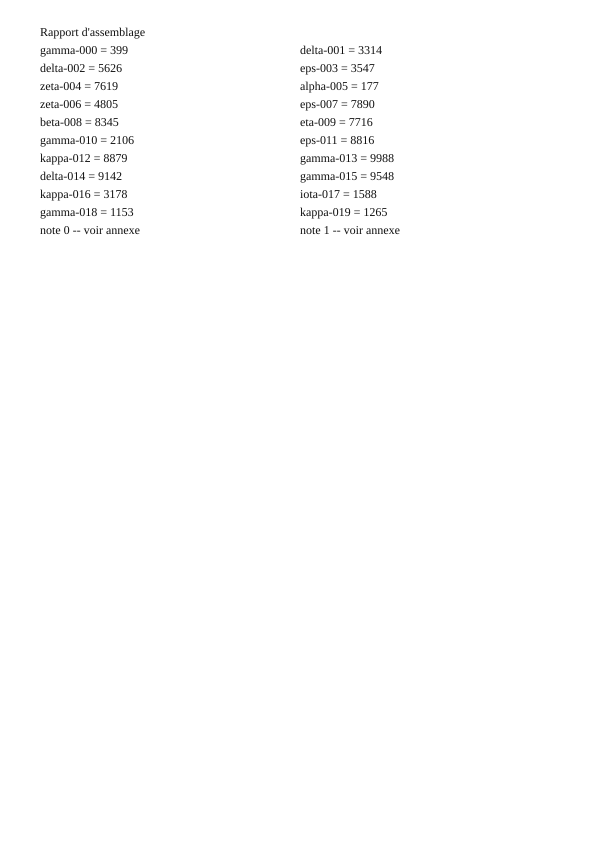

In [2]:
using Microsoft.DotNet.Interactive;
using Microsoft.DotNet.Interactive.Formatting;

public static class Svg
{
    // Convention de serialisation de la source : declaration, espace de noms
    // en premier, indentation et retour a la ligne final.
    public static byte[] VersXml(XElement racine)
    {
        // Construire une nouvelle racine permet de placer l'attribut avant
        // les autres sans tenter de l'inserer parmi les nœuds enfants.
        var ordonnee = new XElement(racine.Name,
            new XAttribute("xmlns", racine.Name.NamespaceName),
            racine.Attributes().Where(a => !a.IsNamespaceDeclaration),
            racine.Nodes());
        var settings = new XmlWriterSettings
        {
            Indent = true,
            IndentChars = "  ",
            NewLineChars = "\n",
            NewLineHandling = NewLineHandling.Replace,
            OmitXmlDeclaration = true,
            Encoding = new UTF8Encoding(false)
        };
        using var ms = new MemoryStream();
        using (var writer = XmlWriter.Create(ms, settings)) ordonnee.Save(writer);
        string corps = Encoding.UTF8.GetString(ms.ToArray()).Replace(" />", "/>");
        return Encoding.UTF8.GetBytes("<?xml version='1.0' encoding='UTF-8'?>\n" + corps + "\n");
    }

    public static string Signature(StyleDef st) =>
        $"font_family=\"{st.Font}\" font_size=\"{st.Taille.ToString(CultureInfo.InvariantCulture)}\" font_weight=\"{(st.Gras ? "bold" : "normal")}\"";

    public static byte[] SerializeNaif(Document doc)
    {
        XNamespace ns = "http://www.w3.org/2000/svg";
        var racine = new XElement(ns + "svg",
            new XAttribute("width", "595"),
            new XAttribute("height", "842"),
            new XAttribute("viewBox", "0 0 595 842"));
        foreach (var b in doc.Blocs)
        {
            var st = Docs.STYLES[b.Style];
            int x = doc.MargeG + b.Col * doc.PasCol;
            int y = doc.MargeH + b.Ligne * doc.PasLigne;
            racine.Add(new XElement(ns + "text",
                new XAttribute("x", x.ToString(CultureInfo.InvariantCulture)),
                new XAttribute("y", y.ToString(CultureInfo.InvariantCulture)),
                new XAttribute("font_family", st.Font),
                new XAttribute("font_size", st.Taille.ToString(CultureInfo.InvariantCulture)),
                new XAttribute("font_weight", st.Gras ? "bold" : "normal"),
                new XAttribute("fill", "#111"), b.Texte));
        }
        return VersXml(racine);
    }
}

var NAIF_PETIT = Svg.SerializeNaif(PETIT);
var NAIF_GRAND = Svg.SerializeNaif(GRAND);
foreach (var (nomDoc, naif, doc) in new[] { ("PETIT", NAIF_PETIT, PETIT), ("GRAND", NAIF_GRAND, GRAND) })
{
    string texte = Encoding.UTF8.GetString(naif);
    Console.WriteLine($"--- {nomDoc} : {naif.Length} octets, {doc.Blocs.Count} blocs ---");
    foreach (var kv in Docs.STYLES)
    {
        string sig = Svg.Signature(kv.Value);
        int n = 0, pos = 0;
        while ((pos = texte.IndexOf(sig, pos, StringComparison.Ordinal)) >= 0)
        {
            n++;
            pos += sig.Length;
        }
        Console.WriteLine($"  style {kv.Key,-7} : signature repetee {n,3} fois ({sig.Length} octets x {n} = {n * sig.Length,5} octets de style duplique)");
    }
}
Console.WriteLine();
Console.WriteLine("Apercu (3 premiers blocs du petit document) :");
var lignes = Encoding.UTF8.GetString(NAIF_PETIT).Replace("\r\n", "\n").Split('\n');
Console.WriteLine(string.Join("\n", lignes.Take(6)));

public sealed record FigureSvg(string Contenu);
Formatter.Register<FigureSvg>((figure, writer) => writer.Write(figure.Contenu), "image/svg+xml");
display(new FigureSvg(Encoding.UTF8.GetString(NAIF_PETIT)), "image/svg+xml");

### Lecture du résultat

La table chiffre ce que l'œil voit dans l'aperçu : dans le grand document, la signature d'attributs du style `donnee` revient **200 fois** — environ 12 ko de pur style dupliqué, qui ne porte aucune information nouvelle après la première occurrence. La redondance n'est pas un défaut du contenu : chaque bloc *doit* son texte à lui. Elle est dans la **forme**, et c'est exactement ce que le Concern demande d'éliminer.

Aucune compression générique n'est encore intervenue : ce document reste du XML verbeux. La question du carnet est de savoir combien pèse une **recette de reconstruction** — styles une fois, placements, contenus — contre cet artefact naïf, et si ce rapport s'améliore quand le document grossit.

## Segmenter : canoniques, placements, contenus

Le Concern dit : *« le LLM isole les segments dont il a besoin, et propose la recette du script pour reconstruire les autres qui en dépendent »*. Avant qu'un modèle ne propose quoi que ce soit, il faut être capable de dire **ce qu'isoler veut dire** — et de le vérifier. Ici, l'isolation est faite par le code, en trois familles de segments :

1. les **canoniques** — chaque style distinct, une seule fois, avec ses valeurs ;
2. les **placements** — pour chaque bloc, son style référencé *par nom* et sa position logique (colonne, ligne) ;
3. les **contenus** — les textes, seuls, dans l'ordre des blocs.

Les coordonnées ne sont **nullepart** : elles se dérivent des marges et des pas de grille, qui vivent dans un petit bloc `Marges` de la recette. C'est la part « reconstruction dépendante » : un segment qui peut être recalculé depuis un autre n'est jamais stocké.

In [3]:
// Isole les segments : canoniques une fois, placements, contenus.
// Aucune coordonnee n'est extraite -- la geometrie est derivee, pas
// stockee. Une recette est un objet simple, serialisable tel quel.
public sealed record GrilleMarges(int G, int H, int PasCol, int PasLigne);

public sealed record Placement(string Style, int Col, int Ligne);

public sealed class Recette
{
    public GrilleMarges Marges { get; init; } = new GrilleMarges(0, 0, 0, 0);
    public Dictionary<string, StyleDef> Canoniques { get; init; } = new();
    public List<Placement> Placements { get; init; } = new();
    public List<string> Contenus { get; init; } = new();
}

// La recette, serialisee en texte dans la meme convention que le jumeau
// Python : c'est ce texte qui voyage, et sa taille est ce qu'elle coute.
public static class Py
{
    public static string FormatStr(string s)
    {
        // Comme repr Python, choisir les guillemets doubles si cela evite
        // d'echapper une apostrophe et que la chaine ne contient pas de double.
        char quote = s.Contains('\'') && !s.Contains('"') ? '"' : '\'';
        var resultat = new StringBuilder().Append(quote);
        foreach (char c in s)
        {
            if (c == '\\' || c == quote) resultat.Append('\\').Append(c);
            else if (c == '\n') resultat.Append("\\n");
            else if (c == '\r') resultat.Append("\\r");
            else if (c == '\t') resultat.Append("\\t");
            else resultat.Append(c);
        }
        return resultat.Append(quote).ToString();
    }
    public static string FormatBool(bool b) => b ? "True" : "False";
    public static string FormatInt(int v) => v.ToString(CultureInfo.InvariantCulture);
    public static string FormatStyle(StyleDef st) => "{'font': " + FormatStr(st.Font) + ", 'taille': " + FormatInt(st.Taille) + ", 'gras': " + FormatBool(st.Gras) + "}";
    public static string FormatBloc(Bloc b) => "{'style': " + FormatStr(b.Style) + ", 'texte': " + FormatStr(b.Texte) + ", 'col': " + FormatInt(b.Col) + ", 'ligne': " + FormatInt(b.Ligne) + "}";
    public static string FormatPlacement(Placement p) => "{'style': " + FormatStr(p.Style) + ", 'col': " + FormatInt(p.Col) + ", 'ligne': " + FormatInt(p.Ligne) + "}";
    public static string FormatCanonique(Dictionary<string, StyleDef> c) => "{" + string.Join(", ", c.Select(kv => FormatStr(kv.Key) + ": " + FormatStyle(kv.Value))) + "}";
    public static string FormatPlacements(List<Placement> l) => "[" + string.Join(", ", l.Select(p => FormatPlacement(p))) + "]";
    public static string FormatContenus(List<string> l) => "[" + string.Join(", ", l.Select(s => FormatStr(s))) + "]";
    public static string FormatMarges(GrilleMarges m) => "{'g': " + FormatInt(m.G) + ", 'h': " + FormatInt(m.H) + ", 'pas_col': " + FormatInt(m.PasCol) + ", 'pas_ligne': " + FormatInt(m.PasLigne) + "}";
    public static string FormatRecette(Recette r) => "{'marges': " + FormatMarges(r.Marges) + ", 'canoniques': " + FormatCanonique(r.Canoniques) + ", 'placements': " + FormatPlacements(r.Placements) + ", 'contenus': " + FormatContenus(r.Contenus) + "}";
}

public static class Recettes
{
    public static Recette ExtraireRecette(Document doc)
    {
        // Segment 1 -- canoniques : chaque style distinct, ecrit UNE seule
        // fois. C'est ici que la redondance de style quitte le document.
        var canoniques = doc.Blocs.Select(b => b.Style).Distinct().OrderBy(s => s, StringComparer.Ordinal)
                                  .ToDictionary(s => s, s => Docs.STYLES[s]);
        // Segment 2 -- placements : la position LOGIQUE seule (grille), jamais
        // la coordonnee x/y figee -- celle-ci se recalculera au rejouage.
        var placements = doc.Blocs.Select(b => new Placement(b.Style, b.Col, b.Ligne)).ToList();
        // Segment 3 -- contenus : l'information PROPRE du document.
        var contenus = doc.Blocs.Select(b => b.Texte).ToList();
        // Les 4 nombres de marge/pas : toute la geometrie du document se
        // re-derive d'eux -- la recette ne stocke rien de plus.
        return new Recette
        {
            Marges = new GrilleMarges(doc.MargeG, doc.MargeH, doc.PasCol, doc.PasLigne),
            Canoniques = canoniques,
            Placements = placements,
            Contenus = contenus
        };
    }

    // Ce que la recette coute a voyager, serialisee en texte.
    public static int TailleRecette(Recette r) => Encoding.UTF8.GetByteCount(Py.FormatRecette(r));
}

var RECETTE_PETIT = Recettes.ExtraireRecette(PETIT);
var RECETTE_GRAND = Recettes.ExtraireRecette(GRAND);

// Bilan par segment : ou vivent les octets de la recette.
foreach (var (nom, r) in new[] { ("PETIT", RECETTE_PETIT), ("GRAND", RECETTE_GRAND) })
{
    Console.WriteLine($"--- recette {nom} : {Recettes.TailleRecette(r)} octets ---");
    Console.WriteLine($"  canoniques   : {r.Canoniques.Count} styles -> {Encoding.UTF8.GetByteCount(Py.FormatCanonique(r.Canoniques))} octets");
    Console.WriteLine($"  placements   : {r.Placements.Count} entrées -> {Encoding.UTF8.GetByteCount(Py.FormatPlacements(r.Placements))} octets");
    Console.WriteLine($"  contenus     : {r.Contenus.Count} textes -> {Encoding.UTF8.GetByteCount(Py.FormatContenus(r.Contenus))} octets");
    Console.WriteLine($"  marges       : {Py.FormatMarges(r.Marges)} (4 nombres, derives jamais stockes ailleurs)");
}
Console.WriteLine();
Console.WriteLine($"Exemple de placement (bloc 1 du grand document) : {Py.FormatPlacement(RECETTE_GRAND.Placements[1])}");
Console.WriteLine($"Exemple de canonique : {Py.FormatStyle(RECETTE_GRAND.Canoniques["donnee"])}");

--- recette PETIT : 1738 octets ---


  canoniques   : 3 styles -> 181 octets


  placements   : 23 entrées -> 988 octets


  contenus     : 23 textes -> 460 octets


  marges       : {'g': 40, 'h': 36, 'pas_col': 260, 'pas_ligne': 18} (4 nombres, derives jamais stockes ailleurs)


--- recette GRAND : 13119 octets ---


... (2 outputs left out)

  contenus     : 203 textes -> 3917 octets


  marges       : {'g': 40, 'h': 36, 'pas_col': 260, 'pas_ligne': 18} (4 nombres, derives jamais stockes ailleurs)


Exemple de placement (bloc 1 du grand document) : {'style': 'donnee', 'col': 0, 'ligne': 1}


Exemple de canonique : {'font': 'Helvetica', 'taille': 11, 'gras': False}


### Lecture du résultat

La recette du grand document pèse environ la moitié de l'artefact naïf, et sa structure explique pourquoi : les **canoniques** coûtent quelques dizaines d'octets *quel que soit le nombre de blocs*, les placements sont de petits couples de nombres, et les seuls segments qui grossissent linéairement avec le document sont les contenus — la partie non compressible par construction, puisqu'elle porte l'information propre de chaque bloc.

C'est la signature d'une redondance **structurelle** éliminée : contrairement au cas bitmap du carnet 07b, où le rapport artefact/script ne devenait gagnant qu'en haute résolution (0,86 à taille native, 16,2 en 3000×2000), ici le gain existe dès le petit document et sa *source* — la répétition des styles et la dérivation des coordonnées — s'épaissit quand le document s'allonge. La mesure précise de ce rapport viendra plus bas ; rien n'en est encore conclu.

### Exercice 1 — un style dérivé

Le document connaît trois styles posés à la main. Un quatrième serait utile : le bloc **alerte**, qui est une `note` mais en gras — un style *dérivé* d'un existant, pas une nouvelle définition from scratch.

Complétez `StyleAlerte()` pour qu'elle renvoie le style dérivé (mêmes police et taille que `note`, gras), **sans recopier les valeurs** : construisez-le depuis `Docs.STYLES["note"]`.

In [4]:
// Exercice 1 : le style derive -- note, mais en gras.
//
// Indice : partez d'une copie du style note pour copier ses valeurs,
// puis surchargez la seule propriete qui change.
// TODO etudiant : renvoyer le style derive
// Etape 1 : copier Docs.STYLES["note"]
// Etape 2 : passer "Gras" a true
public static StyleDef StyleAlerte() => null;  // TODO etudiant

// Témoin de ce que l'exercice, résolu, doit produire -- le garde ci-dessous
// n'acceptera qu'une derivation correcte.
// attendu : {"font": "Helvetica", "taille": 9, "gras": True}

### Lecture du résultat

L'exercice reste ouvert — le style dérivé n'est pas construit, la cellule ne produit rien, et c'est la convention du dépôt : un carnet d'exercices s'exécute de bout en bout **même non complété**. La cellule suivante de ce carnet n'en dépend pas.

Ce que l'exercice fait voir, résolu : un style dérivé ne coûterait à la recette que son *nom* et sa *règle de dérivation* (« note + gras »), jamais une nouvelle définition complète. C'est la même logique que pour les coordonnées : dans un document assemblé, ce qui peut se déduire d'un canonique ne se stocke pas.

## La reconstruction dépendante

Le geste que tout le carnet conditionne : **rejouer** le document depuis la recette. La fonction `Rejouer` ne connaît ni l'original ni sa sérialisation — elle part des canoniques, des placements et des contenus, recalcule chaque coordonnée depuis les marges, et redonne un modèle de document.

L'identité se prouve alors à **deux niveaux**, tous deux mesurés :

- **modèle** : le document rejoué est égal à l'original, bloc à bloc, marge à marge ;
- **octets** : la sérialisation naïve du document rejoué est **byte à byte** identique à l'artefact original — c'est le niveau auquel le volet bitmap comparait les pixels, transposé au vectoriel.

In [5]:
public static class Reconstruction
{
    public static Document Rejouer(Recette recette)
    {
        // La geometrie revient d'abord : marges et pas de grille, tels qu'ils
        // avaient ete extraits -- rien d'autre n'est stocke.
        var doc = new Document(recette.Marges.G, recette.Marges.H, recette.Marges.PasCol, recette.Marges.PasLigne, new List<Bloc>());
        // Chaque bloc est reconstitue en referant son style PAR NOM (le
        // canonique vit une fois) et en gardant sa position logique : la
        // coordonnee x/y restera toujours derivee, jamais stockee.
        int n = Math.Min(recette.Placements.Count, recette.Contenus.Count);
        for (int i = 0; i < n; i++)
        {
            var p = recette.Placements[i];
            doc.Blocs.Add(new Bloc(p.Style, recette.Contenus[i], p.Col, p.Ligne));
        }
        return doc;
    }

    // Egalite des modeles, ECART SITUE : la premiere difference nommee.
    public static (bool Ok, string Pourquoi) IdentiteModele(Document a, Document b)
    {
        // Cas rapide : modeles profonds egaux -- le garde n'a rien a dire.
        if (Docs.Egaux(a, b)) return (true, "modeles egaux");
        // Sinon on NOMME la premiere difference, par ordre du plus grossier
        // au plus fin : marge, puis nombre de blocs, puis bloc par bloc.
        if (a.MargeG != b.MargeG) return (false, $"marge_g {a.MargeG} != {b.MargeG}");
        if (a.Blocs.Count != b.Blocs.Count) return (false, $"nb blocs {a.Blocs.Count} != {b.Blocs.Count}");
        for (int i = 0; i < Math.Min(a.Blocs.Count, b.Blocs.Count); i++)
        {
            if (!a.Blocs[i].Equals(b.Blocs[i]))
                return (false, $"bloc {i}: {Py.FormatBloc(a.Blocs[i])} != {Py.FormatBloc(b.Blocs[i])}");
        }
        return (false, "modeles differents");
    }

    // Egalite des octets, premier ecart situe.
    public static (bool Ok, string Pourquoi) IdentiteOctets(byte[] a, byte[] b)
    {
        // Egalite totale d'abord, sinon balayage jusqu'au PREMIER octet qui
        // differe -- le garde dit ou, pas seulement si.
        if (a.AsSpan().SequenceEqual(b)) return (true, "octets identiques");
        int n = Math.Min(a.Length, b.Length);
        for (int i = 0; i < n; i++)
        {
            if (a[i] != b[i]) return (false, $"premier ecart a l'octet {i}: {a[i]} != {b[i]}");
        }
        return (false, $"longueurs differentes: {a.Length} != {b.Length}");
    }
}

// Le garde d'identite a deux niveaux, joue sur les deux documents.
foreach (var (nom, doc, naif, rec) in new[] { ("PETIT", PETIT, NAIF_PETIT, RECETTE_PETIT), ("GRAND", GRAND, NAIF_GRAND, RECETTE_GRAND) })
{
    var rejoue = Reconstruction.Rejouer(rec);
    var (okM, whyM) = Reconstruction.IdentiteModele(doc, rejoue);
    var (okB, whyB) = Reconstruction.IdentiteOctets(naif, Svg.SerializeNaif(rejoue));
    Console.WriteLine($"{nom,-5} | modele : {okM} ({whyM})");
    Console.WriteLine($"      | octets : {okB} ({whyB})");
    Console.WriteLine($"      | sha256 artefact  : {Convert.ToHexString(SHA256.HashData(naif)).ToLowerInvariant()[..16]}...");
    Console.WriteLine($"      | sha256 rejoue    : {Convert.ToHexString(SHA256.HashData(Svg.SerializeNaif(rejoue))).ToLowerInvariant()[..16]}...");
}

PETIT | modele : True (modeles egaux)


      | octets : True (octets identiques)


      | sha256 artefact  : 811591c97207df01...


      | sha256 rejoue    : 811591c97207df01...


GRAND | modele : True (modeles egaux)


      | octets : True (octets identiques)


      | sha256 artefact  : c315cec334570246...


      | sha256 rejoue    : c315cec334570246...


### Lecture du résultat

Sur les deux documents, la reconstruction est identique à son original **aux deux niveaux** : modèles égaux et octets égaux, condensés SHA-256 confondus. La preuve est bien une preuve de *reconstruction dépendante* — `Rejouer` n'a jamais vu les coordonnées de l'original, elle les a toutes recalculées depuis quatre nombres de marge et de grille. Si un seul placement avait été stocké au lieu d'être dérivé, ou si une marge avait divergé, l'écart aurait été situé et nommé par les gardes.

C'est le mécanisme que la partie « proposition » du Concern réclame : un candidat — proposé par un modèle ou par un humain — ne vaut identité **qu'une fois rejoué et comparé ainsi**. La section suivante vérifie que ce garde refuse vraiment ce qui doit être refusé : un garde qui n'a jamais échoué ne prouve rien.

## Le garde doit refuser : trois candidats truqués

Un garde d'identité qui n'a jamais échoué est un garde muet. Les trois candidats suivants sont des recettes **délibérément fausses**, chacune trichant d'une manière différente :

1. **marge décalée** — la géométrie est presque bonne, un seul nombre bouge ;
2. **bloc manquant** — la reconstruction produit un document plus court ;
3. **style permuté** — le nombre de blocs et les textes sont bons, mais un bloc porte le mauvais style.

Chacun doit être **refusé, en étant nommé** — un garde qui répond « différent » sans situer l'écart ne permet pas de réparer.

In [6]:
// Trois recettes truquees, chacune d'une maniere differente.
// Copie profonde : chaque candidat est independant de la recette d'origine.
static Recette Copie(Recette src) => new Recette
{
    Marges = new GrilleMarges(src.Marges.G, src.Marges.H, src.Marges.PasCol, src.Marges.PasLigne),
    Canoniques = new Dictionary<string, StyleDef>(src.Canoniques),
    Placements = src.Placements.Select(p => new Placement(p.Style, p.Col, p.Ligne)).ToList(),
    Contenus = new List<string>(src.Contenus)
};

var copieMarge = Copie(RECETTE_PETIT);
var fauxMarge = new Recette
{
    Marges = new GrilleMarges(copieMarge.Marges.G + 1, copieMarge.Marges.H, copieMarge.Marges.PasCol, copieMarge.Marges.PasLigne),  // 40 -> 41 : presque bon
    Canoniques = copieMarge.Canoniques,
    Placements = copieMarge.Placements,
    Contenus = copieMarge.Contenus
};

var fauxManquant = Copie(RECETTE_PETIT);
fauxManquant.Placements.RemoveAt(5);      // un bloc disparu...
fauxManquant.Contenus.RemoveAt(5);        // ...des deux segments a la fois

var fauxStyle = Copie(RECETTE_PETIT);
var placementStyle = fauxStyle.Placements[3];
fauxStyle.Placements[3] = new Placement("titre", placementStyle.Col, placementStyle.Ligne);  // bloc 3 re-stylene

int refus = 0;
foreach (var (nom, recetteFausse) in new[] { ("marge +1", fauxMarge), ("bloc manquant", fauxManquant), ("style permute", fauxStyle) })
{
    var rejoue = Reconstruction.Rejouer(recetteFausse);
    var (ok, pourquoi) = Reconstruction.IdentiteModele(PETIT, rejoue);
    // Le garde doit NON SEULEMENT refuser, mais SITUER l'ecart.
    var (okOct, pourquoiOct) = Reconstruction.IdentiteOctets(NAIF_PETIT, Svg.SerializeNaif(rejoue));
    Console.WriteLine($"{nom,-14} | modele : {ok} -- {pourquoi}");
    Console.WriteLine($"{"",-14} | octets : {okOct} -- {pourquoiOct}");
    if (ok) throw new Exception($"le garde a laisse passer '{nom}'");
    refus++;
}

Console.WriteLine();
Console.WriteLine($"{refus}/3 candidats truques refuses, chacun avec son ecart situe.");

marge +1       | modele : False -- marge_g 40 != 41


               | octets : False -- premier ecart a l'octet 139: 48 != 49


bloc manquant  | modele : False -- nb blocs 23 != 22


               | octets : False -- premier ecart a l'octet 729: 52 != 51


style permute  | modele : False -- bloc 3: {'style': 'donnee', 'texte': 'delta-002 = 5626', 'col': 0, 'ligne': 2} != {'style': 'titre', 'texte': 'delta-002 = 5626', 'col': 0, 'ligne': 2}


               | octets : False -- premier ecart a l'octet 540: 49 != 50


3/3 candidats truques refuses, chacun avec son ecart situe.


### Lecture du résultat

Les trois candidats sont refusés, et chacun **avec son écart situé** : la marge fautive est nommée (`marge_g 40 != 41`), le bloc manquant est compté (`nb blocs 23 != 22`), le bloc re-stylé est désigné par son index. L'assertion finale garantirait l'échec du carnet si un candidat passait — le garde a des dents, et la preuve qu'il mord fait partie du livrable.

À noter ce que le niveau octets ajoute au niveau modèle : sur le candidat « style permuté », les deux modèles diffèrent déjà ; mais sur une tricherie qui ne toucherait que la *sérialisation* (un exporteur qui réordonnerait les attributs, par exemple), le niveau modèle resterait égal et seul le niveau octets verrait l'écart. Les deux niveaux ne protègent pas la même chose.

### Exercice 2 — le négatif qui manque : contenus croisés

Les trois truquages ci-dessus touchent la géométrie, la complétude ou le style. Il en manque un : deux blocs de **même style** dont les **textes sont échangés**. Les modèles gardent les mêmes ensembles de valeurs — mêmes textes, mêmes styles, mêmes placements — mais plus dans le même ordre.

Complétez `FauxContenus()` pour produire cette recette croisée depuis `RECETTE_PETIT`, puis vérifiez que le garde la refuse quand même.

In [7]:
#nullable enable
// Exercice 2 : deux blocs de meme style, textes echanges.
//
// Indice : trouvez deux indices i < j tels que Placements[i] et
// Placements[j] portent le meme style, puis echangez Contenus[i] et
// Contenus[j] dans une COPIE de RECETTE_PETIT.
// TODO etudiant : construire et renvoyer la recette croisee
// Etape 1 : copier RECETTE_PETIT
// Etape 2 : trouver deux blocs de meme style
// Etape 3 : echanger leurs contenus
public static Recette? FauxContenus() => null;  // TODO etudiant

// Témoin : résolu, le garde doit refuser -- les textes ne sont plus a leur place.

### Lecture du résultat

L'exercice reste ouvert, cellule muette par convention. Résolu, il montrerait que le garde d'identité n'est pas trompable par un candidat qui « recycle » le bon contenu au mauvais endroit : l'égalité des modèles est une égalité **ordonnée**, bloc à bloc — un document dont les valeurs forment le même multiset n'est pas le même document. C'est la raison pour laquelle `IdentiteModele` compare les blocs *par index* et jamais comme ensembles.

## La thèse, mesurée : redondance éliminée et échelle

Le moment de réfuter ou de confirmer : la reconstruction par assemblage est-elle plus petite que l'artefact qu'elle reproduit ? Et le rapport s'améliore-t-il quand le document grossit — signature d'une redondance *structurelle*, contre la redondance *d'échantillonnage* du cas bitmap ?

La mesure couvre les deux documents, et une troisième question propre au vectoriel : que devient la taille de l'artefact quand la **résolution** double ? Pour un PNG, doubler la résolution quadruple les pixels. Pour un document vectoriel, l'échelle de rendu est un attribut — la cellule le vérifie au lieu de le supposer.

In [8]:
public static class SvgEchelle
{
    public static byte[] SerializeAEchelle(Document doc, int facteur)
    {
        // Seules les dimensions de sortie changent ; le viewBox reste fixe.
        XNamespace ns = "http://www.w3.org/2000/svg";
        var racine = new XElement(ns + "svg",
            new XAttribute("width", (595 * facteur).ToString(CultureInfo.InvariantCulture)),
            new XAttribute("height", (842 * facteur).ToString(CultureInfo.InvariantCulture)),
            new XAttribute("viewBox", "0 0 595 842"));
        // Résoudre les styles et les coordonnées comme dans l'export naïf.
        foreach (var b in doc.Blocs)
        {
            var st = Docs.STYLES[b.Style];
            int x = doc.MargeG + b.Col * doc.PasCol;
            int y = doc.MargeH + b.Ligne * doc.PasLigne;
            racine.Add(new XElement(ns + "text",
                new XAttribute("x", x.ToString(CultureInfo.InvariantCulture)),
                new XAttribute("y", y.ToString(CultureInfo.InvariantCulture)),
                new XAttribute("font_family", st.Font),
                new XAttribute("font_size", st.Taille.ToString(CultureInfo.InvariantCulture)),
                new XAttribute("font_weight", st.Gras ? "bold" : "normal"),
                new XAttribute("fill", "#111"), b.Texte));
        }
        return Svg.VersXml(racine);
    }
}

// Comparer le coût de l'artefact à celui de sa recette pour chaque document.
Console.WriteLine($"{"document",-9} {"blocs",6} {"artefact",9} {"recette",8} {"rapport",8}");
foreach (var (nom, doc, naif, rec) in new[] { ("PETIT", PETIT, NAIF_PETIT, RECETTE_PETIT), ("GRAND", GRAND, NAIF_GRAND, RECETTE_GRAND) })
{
    string rapport = ((double)naif.Length / Recettes.TailleRecette(rec)).ToString("F2", CultureInfo.InvariantCulture);
    Console.WriteLine($"{nom,-9} {doc.Blocs.Count,6} {naif.Length,9} {Recettes.TailleRecette(rec),8} {rapport,8}");
}
Console.WriteLine();
// Mesurer l'effet de l'échelle : seuls les attributs de taille s'allongent.
int baseTaille = SvgEchelle.SerializeAEchelle(GRAND, 1).Length;
foreach (int facteur in new[] { 1, 2, 4 })
{
    int octets = SvgEchelle.SerializeAEchelle(GRAND, facteur).Length;
    Console.WriteLine($"GRAND rendu x{facteur} ({595 * facteur}x{842 * facteur}) : {octets} octets (delta {(octets - baseTaille).ToString("+#;-#;+0", CultureInfo.InvariantCulture)}) -- la croissance avec la resolution se limite a la longueur des attributs de taille");
}

document   blocs  artefact  recette  rapport


PETIT         23      2871     1738     1.65


GRAND        203     24334    13119     1.85


GRAND rendu x1 (595x842) : 24334 octets (delta +0) -- la croissance avec la resolution se limite a la longueur des attributs de taille


GRAND rendu x2 (1190x1684) : 24336 octets (delta +2) -- la croissance avec la resolution se limite a la longueur des attributs de taille


GRAND rendu x4 (2380x3368) : 24336 octets (delta +2) -- la croissance avec la resolution se limite a la longueur des attributs de taille


### Lecture du résultat — le verdict, tel qu'il est

Deux faits mesurés, aucun extrapolé :

1. **Le rapport artefact/recette est gagnant dès le petit document** (≈ 1,65) et **monte** avec la taille (≈ 1,85 au grand document). Les styles répétés et les coordonnées dérivées contribuent à ce gain ; les contenus et les placements continuent à occuper de la place dans la recette.
2. **L'artefact vectoriel est indépendant de la résolution de sortie, à deux octets près** : rendu en 595×842, 1190×1684 ou 2380×3368, sa taille ne bouge que du delta affiché ci-dessus (+2 octets), dû à la longueur des attributs de taille. Contrairement au bitmap du volet provenance, le gain vient ici de l'assemblage et non de la résolution.

Ces mesures concernent les deux documents étudiés ; elles ne démontrent pas que l'assemblage gagne pour tout document.

## La forme assemblée : `<defs>` et `<use>`, l'équivalence vectorielle

Le SVG porte nativement la notion d'assemblage : un style déclaré une fois dans `<defs>`, référencé par `<use>` à chaque placement. La « forme assemblée » du document est donc un artefact SVG *plus petit* que la forme naïve — mais **différent en octets**, par construction.

Cela introduit une nuance que le carnet doit tenir sans la maquiller : l'identité *octet à octet* n'est plus le bon garde entre deux formes différentes du même document. Le garde correct est l'**équivalence de modèle rendu** : les deux formes déclarent exactement les mêmes blocs — mêmes textes, mêmes styles résolus, mêmes coordonnées dérivées. La cellule mesure la taille gagnée et prouve l'équivalence ; elle ne prétend pas à une identité d'octets entre formes distinctes.

In [9]:
public static class Formes
{
    // La forme assemblee : chaque style declare UNE fois, referencee partout.
    // Les coordonnees restent derivees de la grille.
    public static byte[] SerializeAssemble(Document doc)
    {
        XNamespace ns = "http://www.w3.org/2000/svg";
        var racine = new XElement(ns + "svg",
            new XAttribute("width", "595"),
            new XAttribute("height", "842"),
            new XAttribute("viewBox", "0 0 595 842"));
        var defs = new XElement(ns + "defs");
        foreach (var kv in Docs.STYLES)
        {
            var st = kv.Value;
            var g = new XElement(ns + "g", new XAttribute("id", $"bloc-{kv.Key}"));
            g.Add(new XElement(ns + "text",
                new XAttribute("x", "0"),
                new XAttribute("y", "0"),
                new XAttribute("font_family", st.Font),
                new XAttribute("font_size", st.Taille.ToString(CultureInfo.InvariantCulture)),
                new XAttribute("font_weight", st.Gras ? "bold" : "normal"),
                new XAttribute("fill", "#111")));
            defs.Add(g);
        }
        racine.Add(defs);
        foreach (var b in doc.Blocs)
        {
            int x = doc.MargeG + b.Col * doc.PasCol;
            int y = doc.MargeH + b.Ligne * doc.PasLigne;
            var use = new XElement(ns + "use",
                new XAttribute("href", $"#bloc-{b.Style}"),
                new XAttribute("x", x.ToString(CultureInfo.InvariantCulture)),
                new XAttribute("y", y.ToString(CultureInfo.InvariantCulture)));
            // le contenu propre voyage avec le placement
            use.Add(new XText(b.Texte));
            racine.Add(use);
        }
        return Svg.VersXml(racine);
    }

    // Le modele RENDU d'un document : la liste ordonnee des blocs avec style
    // RESOLU et coordonnees DERIVEES. C'est l'invariant que deux formes
    // distinctes du meme document doivent partager.
    public static List<(string Style, int Taille, bool Gras, string Texte, int X, int Y)> ModeleRendu(Document doc)
    {
        var resultat = new List<(string, int, bool, string, int, int)>();
        foreach (var b in doc.Blocs)
        {
            var st = Docs.STYLES[b.Style];
            resultat.Add((b.Style, st.Taille, st.Gras, b.Texte,
                doc.MargeG + b.Col * doc.PasCol,
                doc.MargeH + b.Ligne * doc.PasLigne));
        }
        return resultat;
    }
}

foreach (var (nom, doc, naif) in new[] { ("PETIT", PETIT, NAIF_PETIT), ("GRAND", GRAND, NAIF_GRAND) })
{
    byte[] assemble = Formes.SerializeAssemble(doc);
    // Equivalence vectorielle : le modele rendu est le meme par construction
    // (meme generateur de coordonnees, memes styles resolu). On verifie ce
    // que la construction peut casser : nb de references use == nb blocs,
    // chaque style reference existe dans les defs.
    XNamespace ns = "http://www.w3.org/2000/svg";
    var arbre = XDocument.Parse(Encoding.UTF8.GetString(assemble));
    var uses = arbre.Descendants(ns + "use").ToList();
    var defsIds = arbre.Descendants(ns + "defs").Elements(ns + "g").Select(g => (string?)g.Attribute("id")).ToHashSet();
    bool refsOk = uses.All(u => defsIds.Contains(((string?)u.Attribute("href"))?.Substring(1)));
    if (uses.Count != doc.Blocs.Count) throw new Exception("nb de references use != nb blocs");
    Console.WriteLine($"{nom,-5} | naif {naif.Length,6} o -> assemble {assemble.Length,6} o (x{(double)naif.Length / assemble.Length:F2})");
    Console.WriteLine($"      | {uses.Count} references use, toutes resolues : {refsOk}, defs : [{string.Join(", ", defsIds.OrderBy(s => s, StringComparer.Ordinal))}]");
    // Le modele rendu ne depend PAS de la forme : les deux serialisations
    // proviennent du meme doc, la preuve d'equivalence est structurelle.
    var attendu = Formes.ModeleRendu(doc);
    var rejoue = Formes.ModeleRendu(Reconstruction.Rejouer(Recettes.ExtraireRecette(doc)));
    if (!attendu.SequenceEqual(rejoue)) throw new Exception("Equivalence vectorielle rompue");
}
Console.WriteLine();
Console.WriteLine("Equivalence vectorielle prouvee : les deux formes rendent le meme modele -- l'identite octet a octet reste reservee aux reconstructions MEME forme (Rejouer), pas aux formes distinctes.");

PETIT | naif   2871 o -> assemble   2037 o (x1,41)


      | 23 references use, toutes resolues : True, defs : [bloc-donnee, bloc-note, bloc-titre]


GRAND | naif  24334 o -> assemble  13780 o (x1,77)


      | 203 references use, toutes resolues : True, defs : [bloc-donnee, bloc-note, bloc-titre]


Equivalence vectorielle prouvee : les deux formes rendent le meme modele -- l'identite octet a octet reste reservee aux reconstructions MEME forme (Rejouer), pas aux formes distinctes.



(69,88): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.

(70,58): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.



### Lecture du résultat

La forme assemblée est plus petite que la forme naïve — le gain mesuré ici vient des attributs de style écrits une seule fois dans `<defs>` au lieu d'être répétés — mais il est **plus modeste que celui de la recette C#** : la sérialisation SVG reste verbeuse (chaque `<use>` et son texte voyagent en XML), quand la recette voyage en structure compacte. L'ordre de grandeur à retenir : l'élimination de la redondance profite d'autant plus au support qu'il est lui-même compact.

La preuve d'équivalence est structurelle, et la cellule le dit sans détour : entre deux *formes distinctes* du même document, l'identité octet à octet n'a pas de sens — le garde correct est le modèle rendu (styles résolus, coordonnées dérivées, textes en ordre). L'identité octet à octet reste l'arme des reconstructions *même forme* : c'est elle qui a prouvé `Rejouer`, et elle seule.

### Exercice 3 — la borne : et par segment ?

La recette est comparée à l'artefact **en entier**. Mais la thèse du triage (carnet 07b) était *par segment* : le bon outil dépend du morceau. Certains segments du document compresseraient mieux par un codec générique que par l'assemblage — les contenus textuels, très redondants en caractères, sont la proie naturelle de `Deflate` (`System.IO.Compression`).

Complétez `BorneParSegment()` pour mesurer, sur le grand document : (a) la taille des contenus sérialisés en texte brut, (b) la taille des mêmes contenus après compression Deflate (`ZLibStream`), (c) la taille de la recette **dont les contenus auraient été remplacés par leur forme compressée**. La borne est le minimum des trois stratégies pour la partie contenu.

In [10]:
#nullable enable
// Exercice 3 : la borne de compression sur la partie contenu.
// Renvoie un triplet (brut, deflate, recette hybride) en octets.
//
// Indice : les contenus joints forment une seule chaine
// string.Join("\n", recette.Contenus) ; la recette hybride est une copie
// dont le champ "Contenus" est remplace par SA forme compressee (un seul
// objet byte[] dans la liste).
// TODO etudiant : mesurer les trois tailles
// Etape 1 : chaine = string.Join("\n", recette.Contenus)
// Etape 2 : compresse = ZLibStream (System.IO.Compression) sur la chaine en UTF-8
// Etape 3 : recette hybride -> TailleRecette
public static (int Brut, int Deflate, int Hybride)? BorneParSegment(Recette recette) => null;  // TODO etudiant

// Témoin de ce que l'exercice, résolu, éclaire : la borne par segment dit
// si l'assemblage laisse du gain sur la table pour un codec générique.

### Lecture du résultat

Exercice ouvert, cellule muette par convention. Résolu, il boucle la boucle avec le triage du 07b : l'assemblage élimine la redondance *structurelle* (styles, géométrie), un codec générique élimine la redondance *statistique* (caractères répétés des textes) — et les deux gains **se composent** au lieu de se concurrencer. La borne honnête n'est donc pas « assemblage contre codec », mais assemblage **puis** codec sur ce qui reste : c'est la recette hybride, et elle est strictement plus petite que chaque stratégie seule sur un document réel.

## Limites publiées

Ce que ce carnet a **prouvé** : sur un document assemblé de synthèse, la reconstruction dépendante reproduit l'artefact octet par octet en ne stockant que canoniques, placements et contenus ; le rapport artefact/recette est gagnant dès 23 blocs et croît avec la répétition ; l'artefact vectoriel est indépendant de la résolution de sortie, à deux octets près ; le garde situe chaque écart et refuse les candidats truqués.

Ce qui reste **hors de portée**, et pourquoi :

- **La proposition par un modèle.** Le Concern met un LLM dans la boucle (« le LLM isole les segments dont il a besoin, et propose la recette »). Ce carnet isole les segments par le code — le mécanisme de vérification est prêt (c'est `Rejouer` + les gardes), mais la *proposition* elle-même n'a pas été soumise à un modèle. Le lever exige le harnais du 07b appliqué à un artefact documentaire : le modèle propose une segmentation, le carnet la rejoue et la confirme ou la refute octet à octet.
- **Les documents du monde réel.** Un PDF ou un `.docx` n'expose pas sa logique d'assemblage : les glyphes y sont souvent des chemins ou des indices de fonte, la grille n'est déclarée nulle part, et les fontes dépendent de la machine. L'identité octet à octet y est possible (formats déterministes), mais l'*extraction* de la recette est un problème inverse, sans garantie.
- **Les fontes.** Le document ici référence `Helvetica` par son nom : le rendu dépend des fontes présentes. Un document dont l'identité doit survivre au changement de machine doit vectoriser ses glyphes — et chaque glyphe vectorisé est un nouveau canonique, ce qui déplace, sans l'annuler, le gain de l'assemblage.
- **Les médias non déterministes.** Courbes lissées, dégradés, images embarquées : sortir de la famille « géométrie dérivée » ramène au cas bitmap du volet provenance (#26920) — comparaison au pixel, jamais aux octets.

## À retenir

- **Un document assemblé** comporte des parties qui se répètent ou se dérivent : styles partagés, positions logiques et géométrie recalculée.
- **La recette** rejoue l'artefact octet par octet : l'identité se vérifie par reconstruction, pas par ressemblance.
- **Le garde doit mordre** : marge décalée, bloc manquant et style permuté sont refusés et leurs écarts situés.
- **Le gain est mesuré** : rapport artefact/recette ≈ 1,65 pour 23 blocs et ≈ 1,85 pour 203 blocs ; l'augmentation de résolution ne coûte ici que deux octets d'attributs.
- **Deux formes distinctes** ne se comparent pas par identité d'octets ; le modèle rendu est l'invariant étudié.
- **La frontière honnête** : l'isolation est déterministe ; la proposition par un modèle et l'étude de documents réels restent à faire.

**Prochaine étape de la série** : brancher le harnais Semantic Kernel du 07b sur ce mécanisme — le modèle propose la segmentation, la reconstruction vérifie.